# Daily ensemble performance by lead day

## Purpose

How fast forecast errors grow, and how well the ensemble spread represents them, for the five ways of initializing the F20TR hindcasts (climatological, ERA5-based hybrid, DART atmosphere, DART land, coupled DART), over the 56 lead days of every start date.

## Inputs

Model: `INPUT_DATA_ROOT/F20TR_ne30pg2_r05_IcoswISC30E3r5_<CONFIG>_<YYYYMMDD>00/<ENxx>/post/{atm,lnd}/180x360_aave/ts/{daily,6hourly}/0yr` (20 members, 4 starts per season; `configs/fcst_init_experiment_config.py`), regenerated over the whole 2-month forecast by `post_process/regen_f20tr_ts.sh`. Reference: ERA5 1-degree (daily means from `ERA5/1x1/daily`, 00Z states of the pressure-level fields from `ERA5/1x1/6hourly`; both built from the hourly 0.25-degree ERA5 by `ERA5/scripts/` in the reference archive), GPCP V3.3 daily (global; `GPCPv3.3/1x1/daily`) precipitation, NOAA OLR (`util/fcst_init_data.py`).

## Method

Daily fields per lead day (lead 1 = the start date): 00Z-24Z means of the 6-hourly output (or the daily means of FLUT/PRECT), and for the pressure-level fields the 00Z state ending each day, verified at the same instant (`util/fcst_init_data.py`). Per region (cos-lat weighted, points valid in every source), pooled over the 4 start dates of a season (`util.fcst_init_skill.lead_scores`): ensemble-mean RMSE and bias, spread (unbiased member variance x (N+1)/N), spread/RMSE, fair CRPS, and the RMSE of each start.

## Outputs

`data/hind_lead_eval/lead_skill/lead_skill_<CONFIG>_<SEASON>_<VAR>.nc`, `lead_skill_windows.csv` (window means); figures in `figure/hind_lead_eval/lead_skill/`: `lead_skill_<SEASON>_<REGION>.png` (RMSE with spread, spread ratio, CRPS by lead day).

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction, ELM layer thicknesses
WORKFLOW_NAME = "hind_lead_eval"

# Initialization configurations (configs/fcst_init_experiment_config.py) and seasons (4 starts each)
CONFIGS = ("CLIM_BASE", "HYB_BASE", "DA_ATM", "DA_LND", "DA_COUPLED")
SEASONS = ("DJF", "JJA")
MAX_LEAD = 56          # lead days (8 weeks)
MAX_MEMBERS = None     # e.g. 4 for a quick test
REQUIRE_ALL_MEMBERS = True  # require every member's stream to be regenerated

VARIABLES = ("Z500", "T850", "U850", "U200", "TMQ", "PSL", "TREFHT", "PRECT", "FLUT")
REGIONS = ("GLOBAL", "LAND", "OCEAN", "NH_POLAR", "NINO3.4", "MAR_CONT", "CONUS")
PLOT_REGIONS = ("GLOBAL", "NH_POLAR")
PLOT_VARIABLES = ("Z500", "T850", "U200", "TREFHT", "PRECT")
WINDOWS = {"days 1-3": (1, 3), "days 4-10": (4, 10), "week 3-4": (15, 28), "week 5-8": (29, 56)}

FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 200

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import balanced_runs, check_configs, init_dates, readiness
from configs.fcst_init_experiment_config import members as config_members
from configs.output_paths import workflow_output_dirs

check_configs(CONFIGS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, "lead_skill", output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(data_root=INPUT_DATA_ROOT, land_support_dir=LAND_SUPPORT_DIR)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")


def members_of(config, season):
    """Members of a configuration in a season (the DA runs use a different 20 DART members per season)."""
    m = config_members(config, season)
    return m if MAX_MEMBERS is None else m[:MAX_MEMBERS]


def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/lead_skill


## 4. Read input

Which members are regenerated (`post/scripts/regen_ts_<stream>.status`). Every configuration must be ready in both seasons (the two start sets hold the same experiments); otherwise the notebook stops and names what is missing. `REQUIRE_ALL_MEMBERS = False` accepts partly regenerated configuration-seasons.

In [4]:
status = readiness(CONFIGS, SEASONS, streams=(("atm", "daily"), ("atm", "6hourly")), data_root=INPUT_DATA_ROOT)
summary = status.groupby(["config", "season"]).agg(ready=("ready", "sum"), members=("members", "sum"))
display(summary.unstack("season"))
RUNS = balanced_runs(status, REQUIRE_ALL_MEMBERS)  # raises unless every configuration is ready in every season
print(f"[RUNS] {len(RUNS)} configuration-seasons: {RUNS}")

ready      members     
season       DJF  JJA     DJF  JJA
config                            
CLIM_BASE    160  160     160  160
DA_ATM       160  160     160  160
DA_COUPLED   160  160     160  160
DA_LND       160  160     160  160
HYB_BASE     160  160     160  160

[RUNS] 10 configuration-seasons: [('CLIM_BASE', 'DJF'), ('CLIM_BASE', 'JJA'), ('DA_ATM', 'DJF'), ('DA_ATM', 'JJA'), ('DA_COUPLED', 'DJF'), ('DA_COUPLED', 'JJA'), ('DA_LND', 'DJF'), ('DA_LND', 'JJA'), ('HYB_BASE', 'DJF'), ('HYB_BASE', 'JJA')]


## 5. Derive and save

Per season and variable the reference is read once; per configuration the 80 member series are loaded, scored, and written. Saved files are reused unless `FORCE_COMPUTE`.

In [5]:
from configs.s2s_config import TCC_REGIONS
from util.fcst_init_data import open_campaign, open_reference, region_masks, spec
from util.fcst_init_skill import lead_scores

regions = [r for r in TCC_REGIONS if r["name"] in REGIONS]
path = lambda c, s, v: data_dir / f"lead_skill_{c}_{s}_{v}.nc"
masks = None
for season in SEASONS:
    inits = init_dates([season])[season]
    for var in VARIABLES:
        todo = [c for c in CONFIGS if (c, season) in RUNS and (FORCE_COMPUTE or not path(c, season, var).exists())]
        if not todo:
            continue
        try:
            ref = open_reference(var, inits, max_lead=MAX_LEAD, observation_root=OBSERVATION_ROOT).load()
        except FileNotFoundError as err:
            print(f"[SKIP] {var}: {err}")
            continue
        if masks is None:
            masks = region_masks(regions, ref.lat.values, ref.lon.values, land_support_dir=LAND_SUPPORT_DIR)
        for c in todo:
            model = open_campaign(c, season, var, members=members_of(c, season), max_lead=MAX_LEAD, **ROOTS).load()
            ds = lead_scores(model, ref, masks).assign_attrs(units=spec(var).units, config=c, season=season,
                                                              variable=var, reference=spec(var).reference)
            ds.to_netcdf(path(c, season, var))
            print(f"[WRITE] {path(c, season, var)}")
            del model
scores = {(s, c, v): xr.load_dataset(path(c, s, v)) for s in SEASONS for c in CONFIGS for v in VARIABLES
          if path(c, s, v).exists()}
print(f"[LOAD] {len(scores)} score files")

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_ATM_JJA_T850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_LND_JJA_T850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_COUPLED_JJA_T850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_ATM_JJA_U850.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_LND_JJA_U850.nc


... (16 outputs left out)

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_ATM_JJA_FLUT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_LND_JJA_FLUT.nc


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_DA_COUPLED_JJA_FLUT.nc


[LOAD] 90 score files


## 6. Scores

Window means of each metric (lead days in `WINDOWS`), per season, region, variable and configuration.

In [6]:
rows = []
for (s, c, v), ds in scores.items():
    for w, (a, b) in WINDOWS.items():
        sub = ds.sel(lead=slice(a, b)).mean("lead")
        for r in sub.region.values:
            rows.append(dict(season=s, config=c, variable=v, region=r, window=w,
                             **{m: float(sub[m].sel(region=r)) for m in ("rmse", "bias", "spread", "spread_ratio", "crps_fair")}))
table = pd.DataFrame(rows)
table.to_csv(data_dir / "lead_skill_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'lead_skill_windows.csv'}")
if len(table):
    display(table[table.region == "GLOBAL"].pivot_table(index=["season", "variable", "config"], columns="window",
                                                        values="rmse", sort=False).round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/lead_skill/lead_skill_windows.csv


window                      days 1-3  days 4-10  week 3-4  week 5-8
season variable config                                             
DJF    Z500     CLIM_BASE     111.29      99.56     82.36     90.21
                HYB_BASE       20.49      61.92     88.01    102.25
                DA_ATM         50.27      75.09     86.38     97.09
                DA_LND         20.75      68.21     95.16    102.70
                DA_COUPLED     50.41      75.21     88.41     97.40
...                              ...        ...       ...       ...
JJA    FLUT     CLIM_BASE      37.38      33.80     27.38     24.94
                HYB_BASE       65.47      53.84     42.73     32.86
                DA_ATM         20.56      25.58     25.40     24.76
                DA_LND         67.64      55.24     43.23     33.03
                DA_COUPLED     20.45      25.59     25.38     24.79

[90 rows x 4 columns]

## 7. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/lead_skill/lead_skill_DJF_GLOBAL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/lead_skill/lead_skill_DJF_NH_POLAR.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/lead_skill/lead_skill_JJA_GLOBAL.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/lead_skill/lead_skill_JJA_NH_POLAR.png


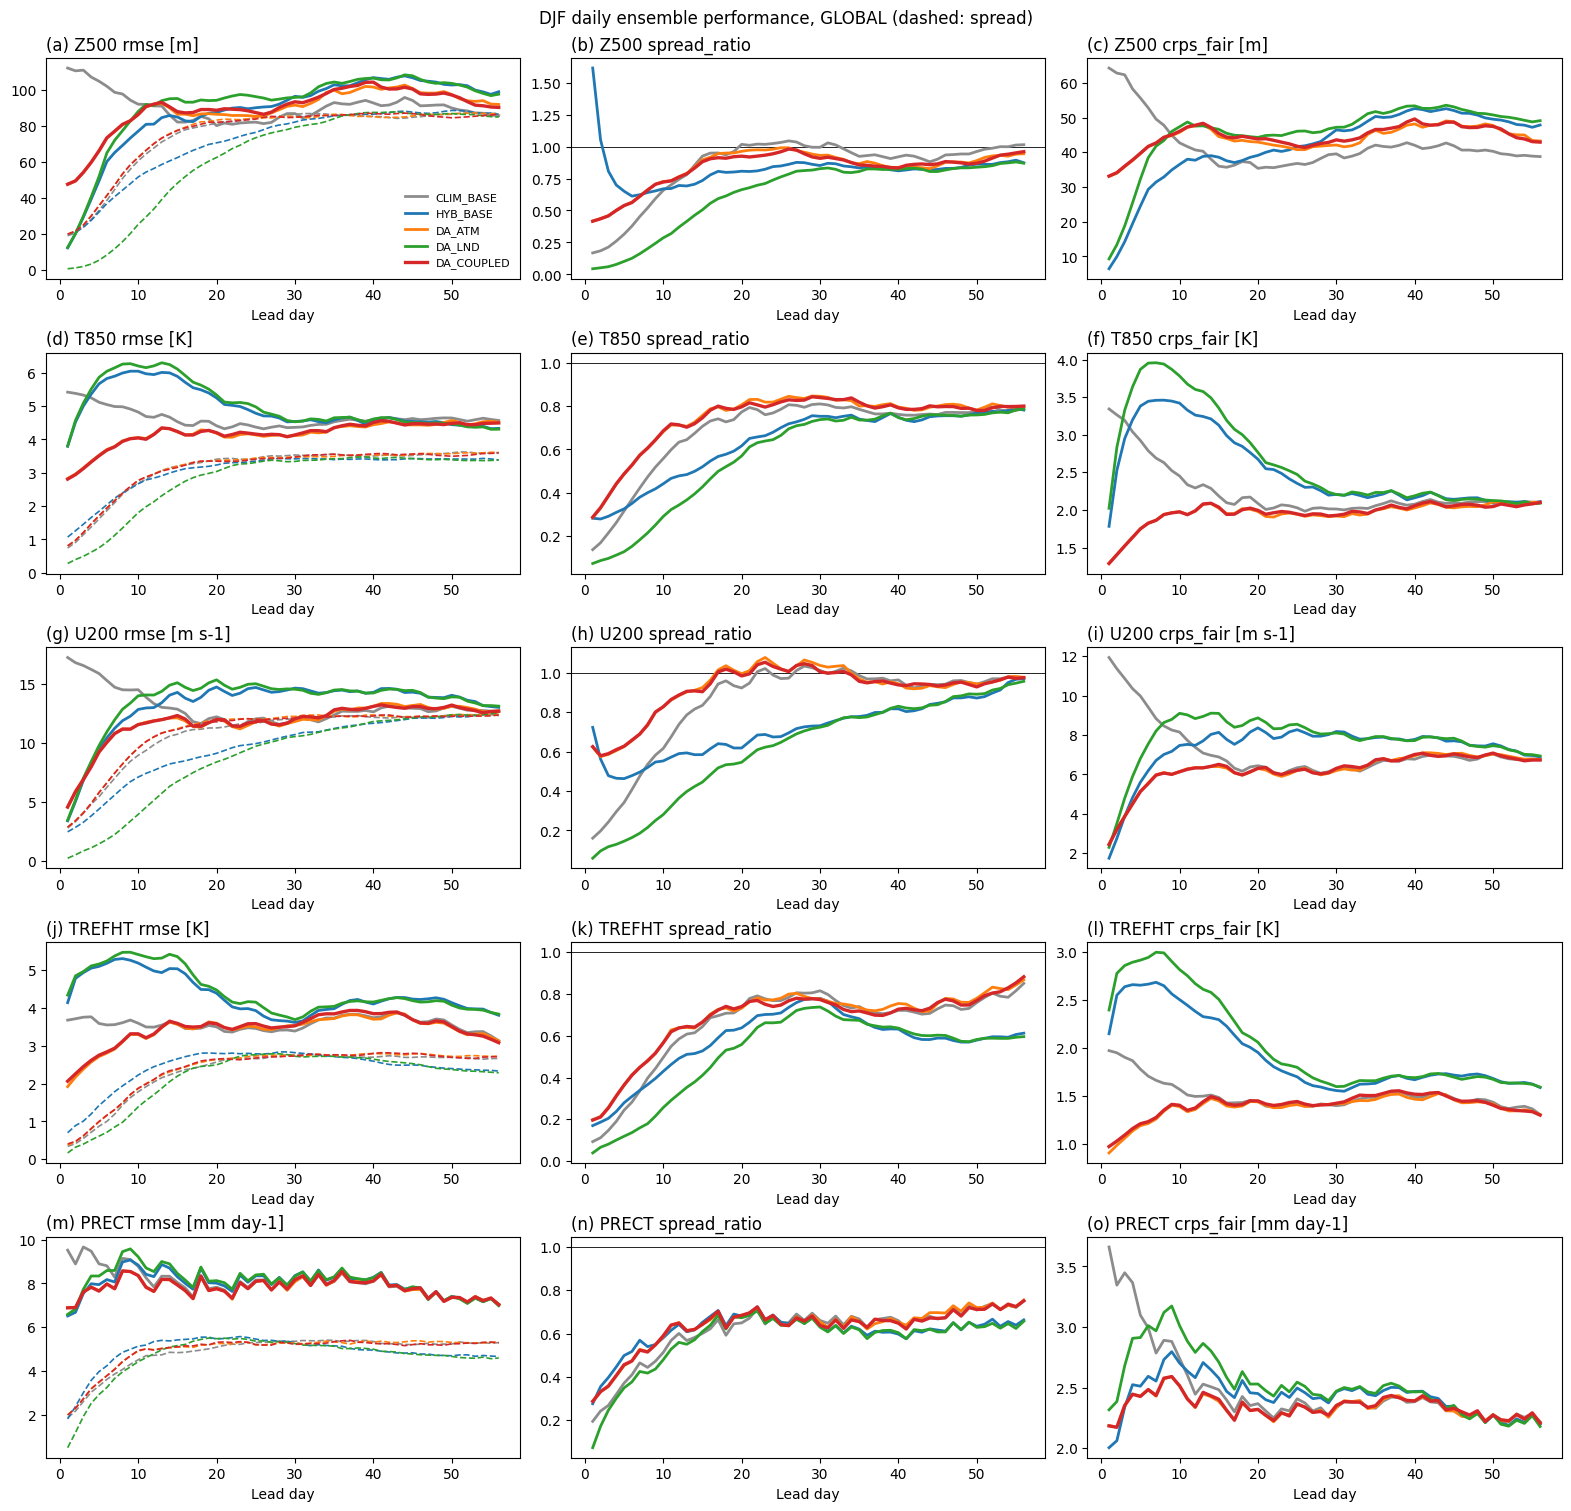

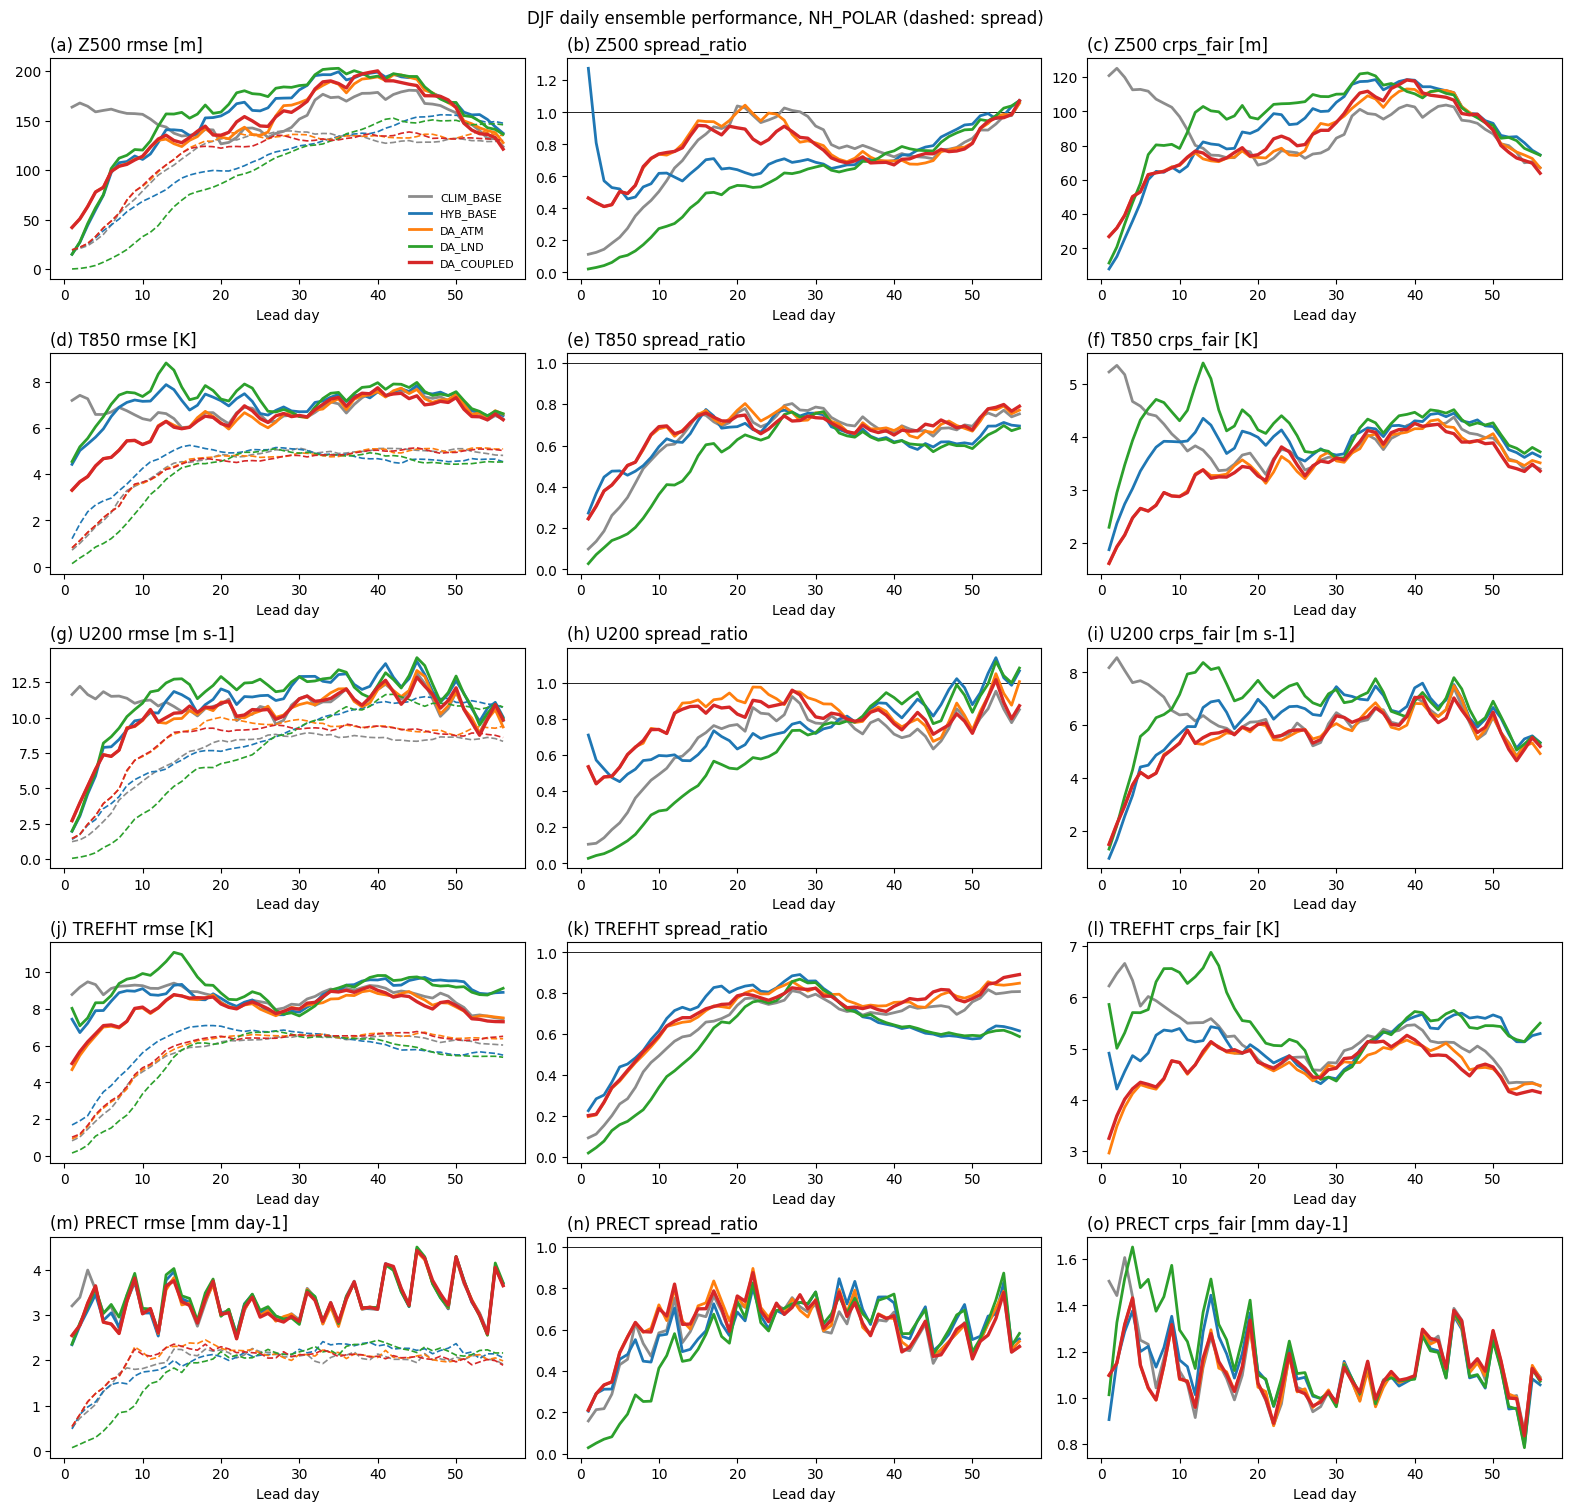

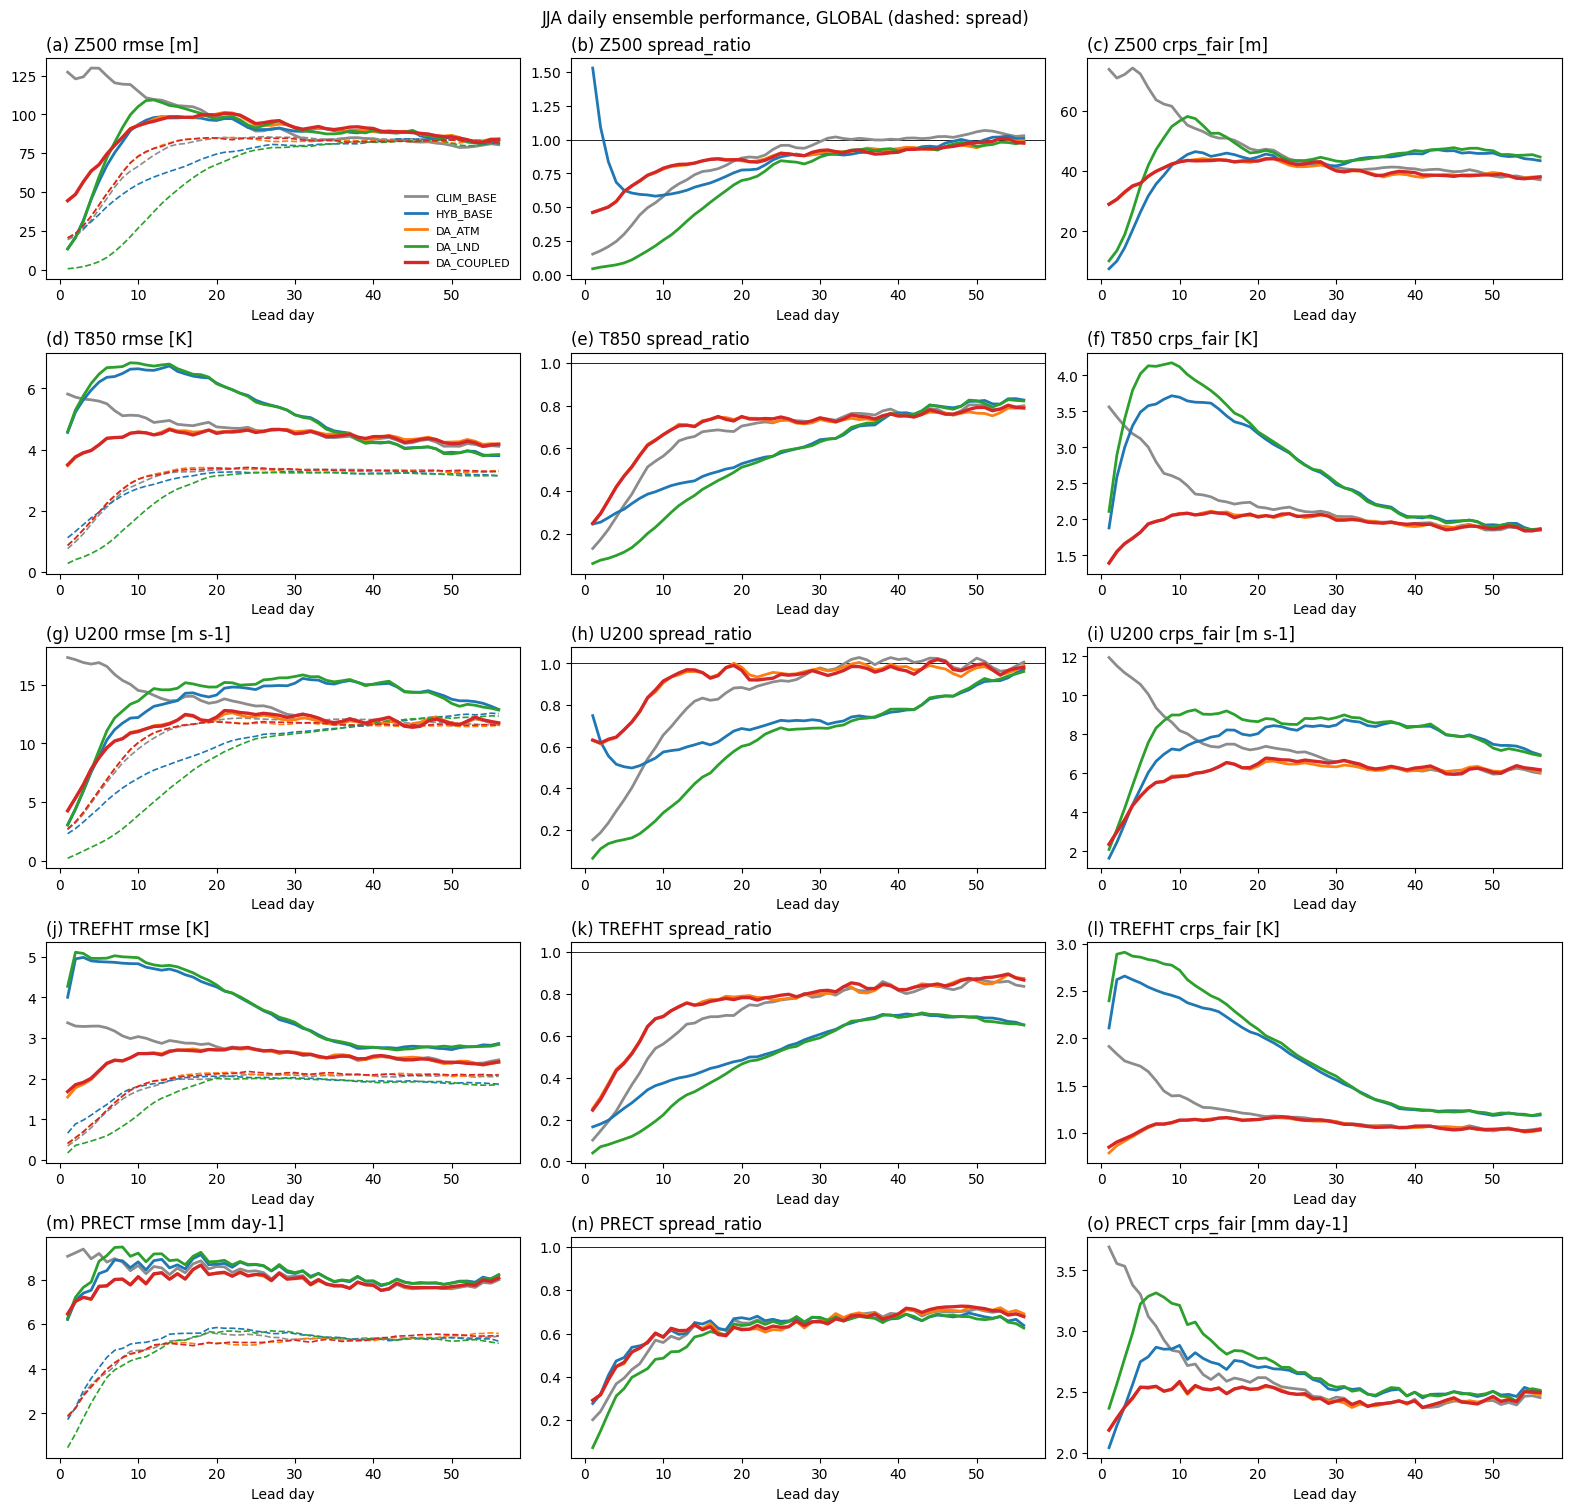

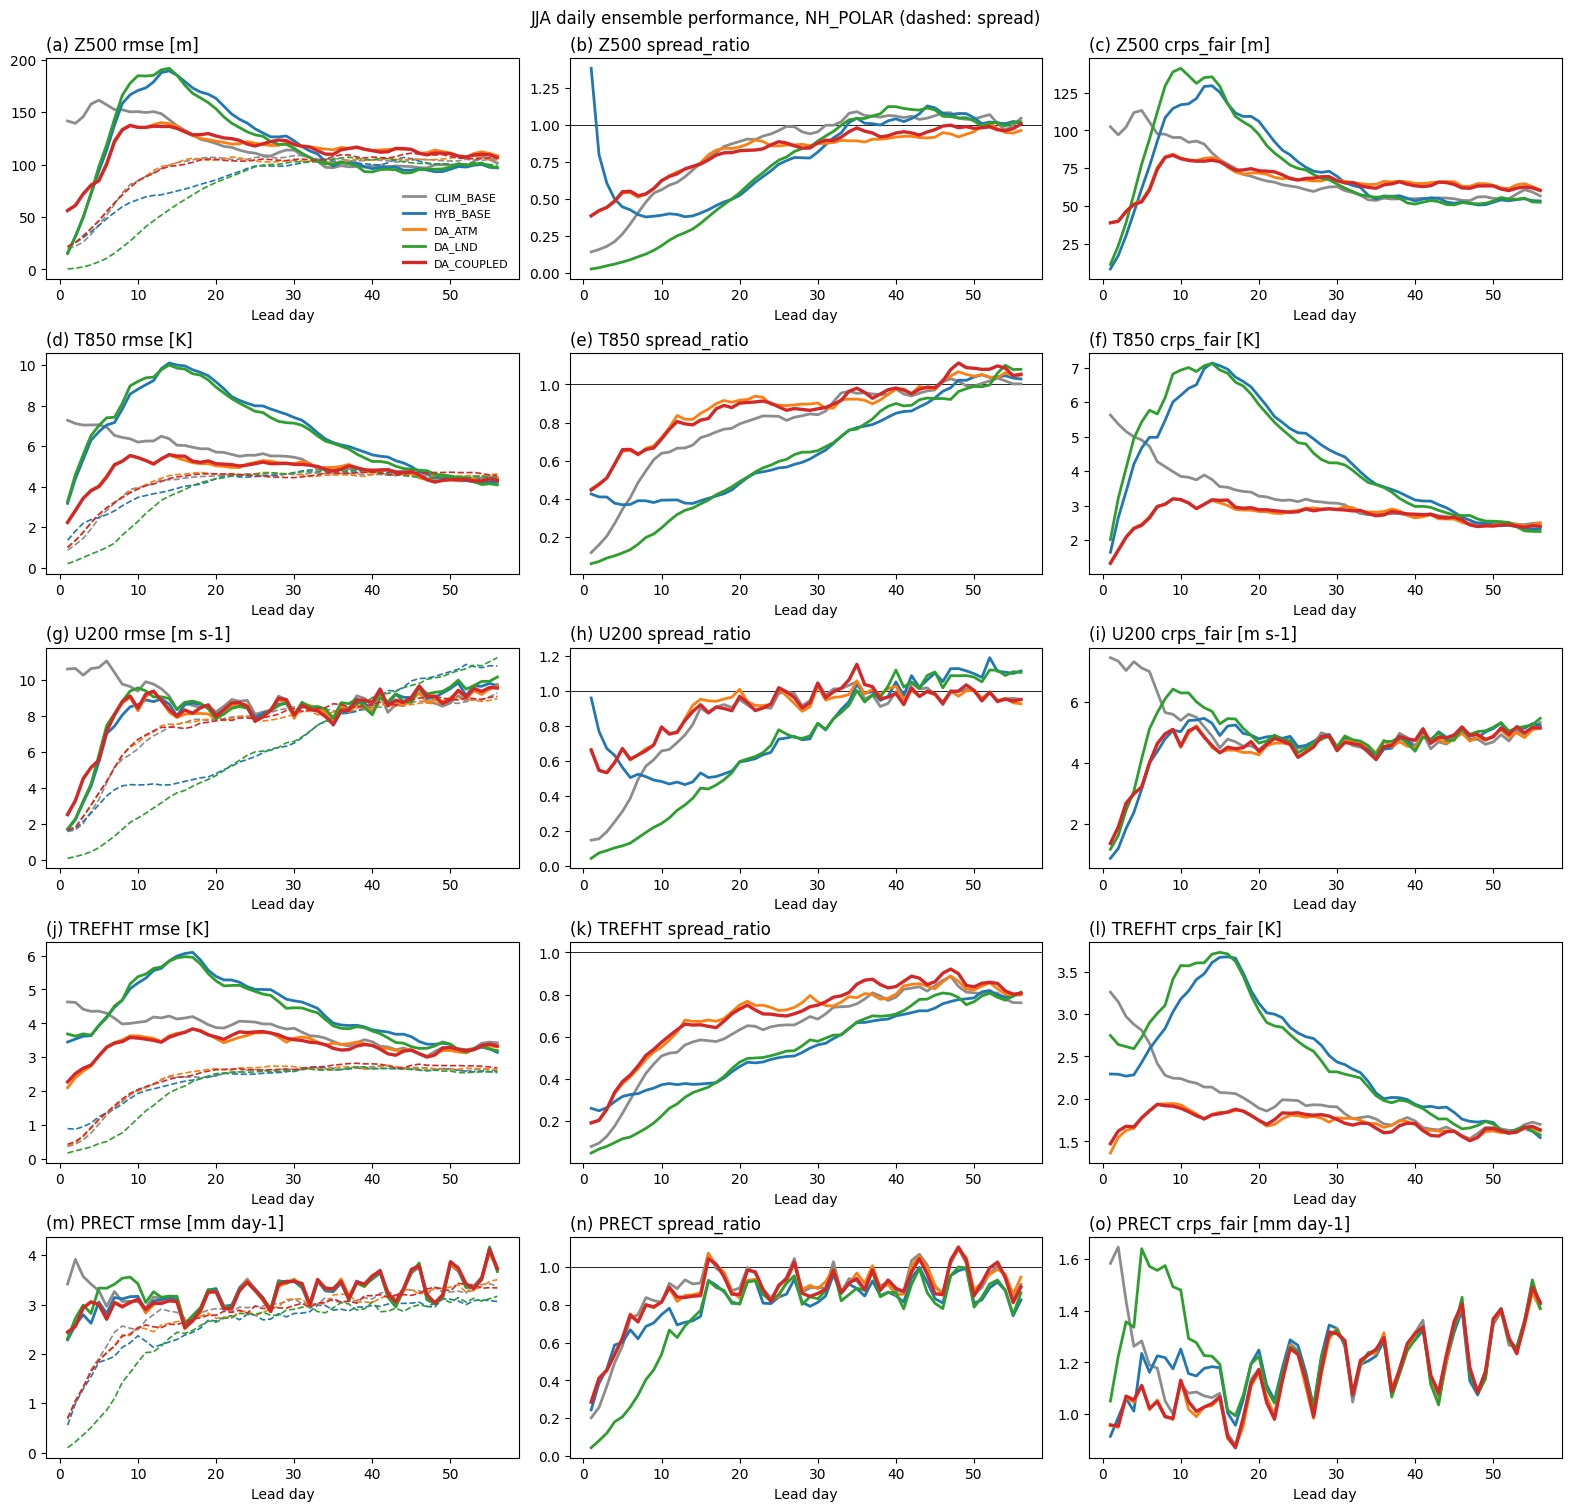

In [7]:
from util.fcst_init_plotting import plot_lead_curves

for s in SEASONS:
    sub = {(c, v): ds for (ss, c, v), ds in scores.items() if ss == s}
    if not sub:
        continue
    for r in PLOT_REGIONS:
        save(plot_lead_curves(sub, PLOT_VARIABLES, region=r, metrics=("rmse", "spread_ratio", "crps_fair"),
                              max_lead=MAX_LEAD, season=s), f"lead_skill_{s}_{r}.png")